In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt

In [2]:
#load data into memory
df = pd.read_csv('data/adult11.csv')

In [5]:
#initial data check
rows, cols = df.shape
print(f'Rows: {rows}')
print(f'Columns: {cols}')

df.head()

Rows: 48842
Columns: 15


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,salary
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,?,103497,Some-college,10,Never-married,?,Own-child,White,Female,0,0,30,United-States,<=50K


In [6]:
df.tail()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,salary
48837,27,Private,257302,Assoc-acdm,12,Married-civ-spouse,Tech-support,Wife,White,Female,0,0,38,United-States,<=50K
48838,40,Private,154374,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0,0,40,United-States,>50K
48839,58,Private,151910,HS-grad,9,Widowed,Adm-clerical,Unmarried,White,Female,0,0,40,United-States,<=50K
48840,22,Private,201490,HS-grad,9,Never-married,Adm-clerical,Own-child,White,Male,0,0,20,United-States,<=50K
48841,52,Self-emp-inc,287927,HS-grad,9,Married-civ-spouse,Exec-managerial,Wife,White,Female,15024,0,40,United-States,>50K


In [7]:
df.describe()

,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week
count,48842.000000,4.884200e+04,48842.000000,48842.000000,48842.000000,48842.000000
mean,38.643585,1.896641e+05,10.078089,1079.067626,87.502314,40.422382
std,13.710510,1.056040e+05,2.570973,7452.019058,403.004552,12.391444
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.175505e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.781445e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.376420e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.490400e+06,16.000000,99999.000000,4356.000000,99.000000


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             48842 non-null  int64
 1   workclass       48842 non-null  str  
 2   fnlwgt          48842 non-null  int64
 3   education       48842 non-null  str  
 4   education-num   48842 non-null  int64
 5   marital-status  48842 non-null  str  
 6   occupation      48842 non-null  str  
 7   relationship    48842 non-null  str  
 8   race            48842 non-null  str  
 9   gender          48842 non-null  str  
 10  capital-gain    48842 non-null  int64
 11  capital-loss    48842 non-null  int64
 12  hours-per-week  48842 non-null  int64
 13  native-country  48842 non-null  str  
 14  salary          48842 non-null  str  
dtypes: int64(6), str(9)
memory usage: 5.6 MB


In [13]:
print(f'Duplicated Rows: {df.duplicated().sum()}')
df = df.drop_duplicates()

Duplicated Rows: 0


In [14]:
df['education'].value_counts()

education
HS-grad         15770
Some-college    10863
Bachelors        8013
Masters          2656
Assoc-voc        2060
11th             1812
Assoc-acdm       1601
10th             1389
7th-8th           954
Prof-school       834
9th               756
12th              655
Doctorate         594
5th-6th           507
1st-4th           245
Preschool          81
Name: count, dtype: int64

In [15]:
subset = df. groupby('education')['fnlwgt'].sum().reset_index()
subset.head

<bound method NDFrame.head of        education      fnlwgt
0           10th   272983724
1           11th   353525318
2           12th   129251530
3        1st-4th    57658082
4        5th-6th   116627557
5        7th-8th   179115747
6            9th   150449180
7     Assoc-acdm   310113821
8      Assoc-voc   369606571
9      Bachelors  1509621616
10     Doctorate   109349744
11       HS-grad  2974410185
12       Masters   481917880
13     Preschool    19345472
14   Prof-school   155612621
15  Some-college  2064361431>

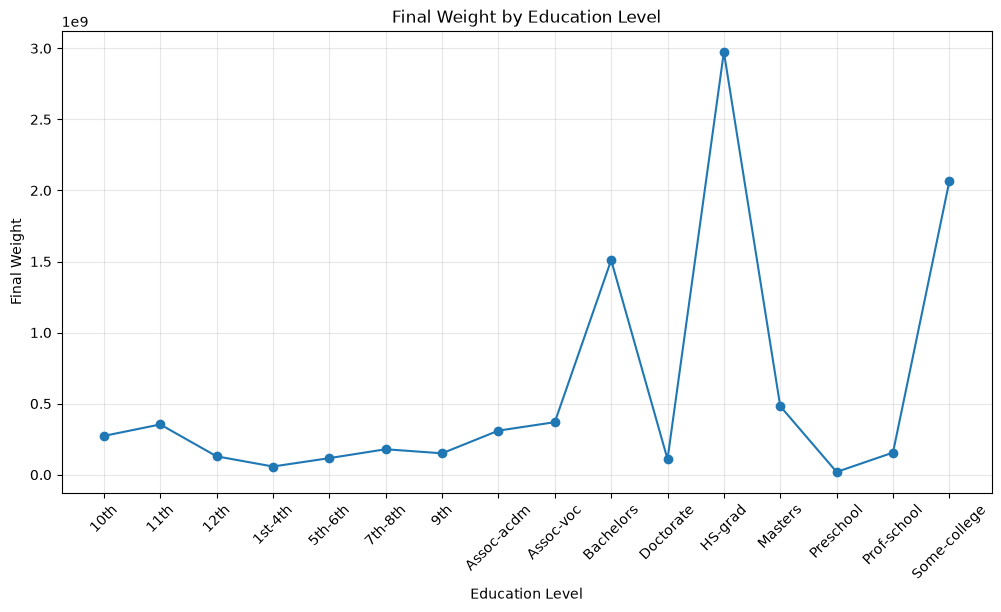

In [16]:
#Process into workable 
plt.figure(figsize=(12, 6))

plt.plot(
    subset['education'],
    subset['fnlwgt'],
    marker='o'
)

plt.title('Final Weight by Education Level')
plt.xlabel('Education Level')
plt.ylabel('Final Weight')

plt.xticks(rotation=45)
plt.grid(alpha=0.3)

plt.show()

In [17]:
median_age = df.groupby('education')['age'].median().reset_index()

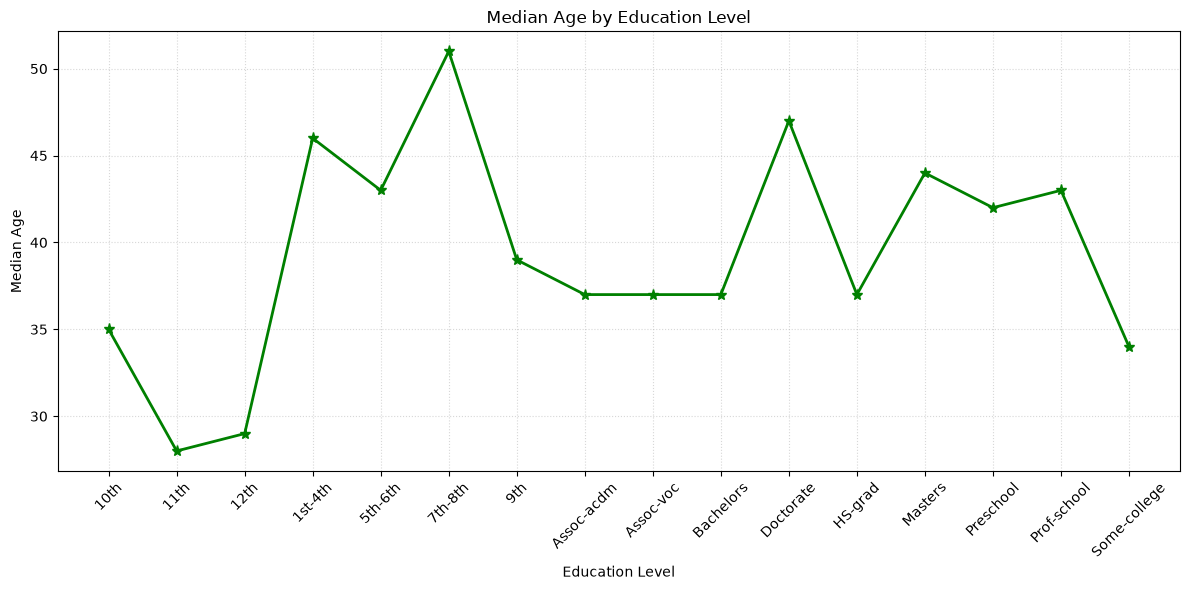

In [21]:
plt.figure(figsize=(12, 6))

plt.plot(
    median_age['education'],
    median_age['age'],
    marker='*',
    color='green',
    linewidth=2,
    markersize=8
)

plt.title('Median Age by Education Level')
plt.xlabel('Education Level')
plt.ylabel('Median Age')

plt.xticks(rotation=45)
plt.grid(linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()